In [7]:
    import subprocess #used to run system commands from script

    #libaries used to interogate results
    import cymetric as cym 
    from cymetric import graphs as cgr
    from cymetric import timeseries

    #Matplotlib is a python library for plotting graphs
    import matplotlib.pyplot as plt

    #Run cyclus
    subprocess.run(["cyclus", "sample_test_data.xml"])


              :                                                               
          .CL:CC CC             _Q     _Q  _Q_Q    _Q    _Q              _Q   
        CC;CCCCCCCC:C;         /_\)   /_\)/_/\\)  /_\)  /_\)            /_\)  
        CCCCCCCCCCCCCl       __O|/O___O|/O_OO|/O__O|/O__O|/O____________O|/O__
     CCCCCCf     iCCCLCC     /////////////////////////////////////////////////
     iCCCt  ;;;;;.  CCCC                                                      
    CCCC  ;;;;;;;;;. CClL.                          c                         
   CCCC ,;;       ;;: CCCC  ;                   : CCCCi                       
    CCC ;;         ;;  CC   ;;:                CCC`   `C;                     
  lCCC ;;              CCCC  ;;;:             :CC .;;. C;   ;    :   ;  :;;   
  CCCC ;.              CCCC    ;;;,           CC ;    ; Ci  ;    :   ;  :  ;  
   iCC :;               CC       ;;;,        ;C ;       CC  ;    :   ; .      
  CCCi ;;               CCC        ;;;.      .C ;   

terminate called after throwing an instance of 'cyclus::ValidationError'
  what():  Error loading xml file: Could not create parser context



CompletedProcess(args=['cyclus', 'sample_test_data.xml'], returncode=-6)

In [13]:
import os
import pathlib
import subprocess
import shutil

print("Current directory:", os.getcwd())
print("Cyclus executable:", shutil.which("cyclus"))
print("XML exists here:", pathlib.Path("sample_test_data.xml").exists())

print("\nFiles in current directory:")
for item in pathlib.Path(".").iterdir():
    print(item.name)

print("\nSearching the workspace for sample_test_data.xml:")
for path in pathlib.Path("/workspaces").rglob("sample_test_data.xml"):
    print(path) 
#*********************************************************************
import os
import subprocess

xml_file = os.path.abspath("sample_test_data.xml")

if not os.path.isfile(xml_file):
    print("XML file not found:", xml_file)
else:
    result = subprocess.run(
        ["cyclus", xml_file],
        capture_output=True,
        text=True
    )

    print("Return code:", result.returncode)
    print("Output:", result.stdout)
    print("Errors:", result.stderr)

Current directory: /workspaces/Fork_Assignment_Cyclus/scripts
Cyclus executable: /root/.local/bin/cyclus
XML exists here: True

Files in current directory:
test_cyclus.sh
sample_test_from_assignment.ipynb
cyclus.sqlite
sample_test_data.xml

Searching the workspace for sample_test_data.xml:
/workspaces/Fork_Assignment_Cyclus/scripts/sample_test_data.xml
Return code: 0
Output:               :                                                               
          .CL:CC CC             _Q     _Q  _Q_Q    _Q    _Q              _Q   
        CC;CCCCCCCC:C;         /_\)   /_\)/_/\\)  /_\)  /_\)            /_\)  
        CCCCCCCCCCCCCl       __O|/O___O|/O_OO|/O__O|/O__O|/O____________O|/O__
     CCCCCCf     iCCCLCC     /////////////////////////////////////////////////
     iCCCt  ;;;;;.  CCCC                                                      
    CCCC  ;;;;;;;;;. CClL.                          c                         
   CCCC ,;;       ;;: CCCC  ;                   : CCCCi              

In [12]:
from pathlib import Path

xml_file = Path("sample_test_data.xml")

print("Current directory:", Path.cwd())
print("File exists:", xml_file.exists())

if xml_file.exists():
    print("File size:", xml_file.stat().st_size, "bytes")
    print("First 500 characters:")
    print(xml_file.read_text(errors="replace")[:500])
    

Current directory: /workspaces/Fork_Assignment_Cyclus/scripts
File exists: True
File size: 5160 bytes
First 500 characters:
<simulation>
<control>
<duration>721</duration>
<startmonth>1</startmonth>
<startyear>2018</startyear>
<decay>never</decay>
<explicit_inventory>true</explicit_inventory>
</control>
<archetypes>
<spec>
<lib>cycamore</lib>
<name>Enrichment</name>
</spec>
<spec>
<lib>cycamore</lib>
<name>Reactor</name>
</spec>
<spec>
<lib>cycamore</lib>
<name>Source</name>
</spec>
<spec>
<lib>cycamore</lib>
<name>Sink</name>
</spec>
<spec>
<lib>cycamore</lib>
<name>Separations</name>
</spec>
<spec>
<lib>cycamore</l


In [11]:
from pathlib import Path

repo = Path("/workspaces/Fork_Assignment_Cyclus")

for file in repo.rglob("*.xml"):
    if ".git" not in file.parts:
        print(f"{file.stat().st_size:>8} bytes  {file}")
        

     312 bytes  /workspaces/Fork_Assignment_Cyclus/packages.xml
     279 bytes  /workspaces/Fork_Assignment_Cyclus/tutorial/tutorial1.xml
    3928 bytes  /workspaces/Fork_Assignment_Cyclus/complete_files/tutorial1_solution.xml
   19789 bytes  /workspaces/Fork_Assignment_Cyclus/complete_files/simple_eg23.xml
    1659 bytes  /workspaces/Fork_Assignment_Cyclus/examples/input2.xml
    2846 bytes  /workspaces/Fork_Assignment_Cyclus/examples/input3.xml
   19673 bytes  /workspaces/Fork_Assignment_Cyclus/examples/eg01-eg23.xml
    1724 bytes  /workspaces/Fork_Assignment_Cyclus/examples/input1.xml
    5160 bytes  /workspaces/Fork_Assignment_Cyclus/scripts/sample_test_data.xml


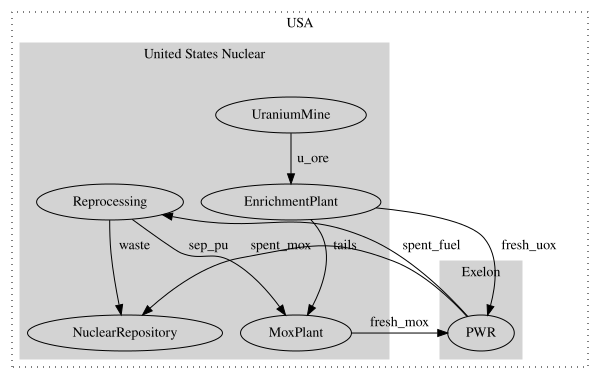

In [14]:
##Continue Running the Expiremental Code: 
#Open up the Python Database
cdb = cym.dbopen("cyclus.sqlite")
ev = cym.Evaluator(db=cdb,write=False)

#Draw the Cycle Diagram 
cgr.flow_graph(ev, label='comm')

<Axes: xlabel='Time'>

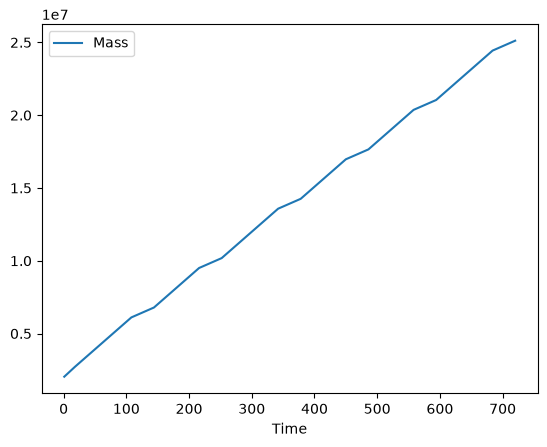

In [15]:
#want the uranium requirement from the mine over time
#This creates a Pandas Dataframe
u=cym.filters.transactions_nuc(ev,commodities=["u_ore"])

#Sum up the nuclides
u = u.groupby("Time")[["Mass"]].sum()

#for plotting in excel
u.to_csv("mined_u.csv")

#plot cumulative in python
u=u.cumsum()
u.plot(y="Mass")

In [16]:
"""There are more elegant ways to output data than using CSV files
The data is stored in dataframes (from the python Pandas library)
But we use CSV as it is simpler"""

#Output all transactions
cym.filters.transactions_nuc(ev).to_csv("transactions.csv")

#look at how tails builds up in MoxPlant and a small amount is then used to make fuel when the Pu is available
m = cym.filters.inventories(ev,facilities=["MoxPlant"])
m = m[m["InventoryName"] == "in_stream_1"].groupby("Time")[["Quantity"]].sum()
m.to_csv("tails_inventory.csv")

m = cym.filters.inventories(ev,facilities=["MoxPlant"])
m = m[m["InventoryName"] == "in_stream_0"].groupby("Time")[["Quantity"]].sum()
m.to_csv("pu_inventory.csv")
